# MTL for DNSSEC: Parsing and Verifying a Full Signature

<div style="border-left: 5px solid #FFC107; background-color: #FFFDF5; padding: 12px; border-radius: 4px; color: #000;">
    <strong>⚠️ Please note:</strong> This notebook builds on <code>1-build_a_mtl.ipynb</code>. Some files used by this notebook are generated by <code>1-build_a_mtl.ipynb</code>.
</div>

This notebook provides a demonstration of the parsing and verification processes for ML-DSA signatures within the context of Merkle Tree Ladder (MTL) for DNSSEC. A detailed description of ML-DSA-MTL for DNSSEC can be found in draft-kaizer-dnsop-ml-dsa-mtl-dnssec-03.

Demo Scenario:
  * A requester queries the A record for a domain.
  * The responder returns the record along with a full signature. This signature includes both the record's authentication path and the signed ladder.

Note: This demo assumes the requester has already fetched and trusted the signer's DNSKEY record.

## 📋 Demo Outline

<div class="alert alert-block alert-info" style="border-left: 20px solid #a8a7a8; border-right: solid #a8a7a8; border-top: solid #a8a7a8; border-bottom: solid #a8a7a8; background-color: #f1f0f2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #757475;">Libraries and Demo Configurations</h3>
<ul>
    <li>Importing Libraries</li>
    <li>Demo Configuration
        <ul>
            <li>Example DNS A Record</li>
            <li>Signing and Hashing Configurations</li>
            <li>Public Key</li>
            <li>MTL Full Signature</li>
        </ul>
    </li>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #c7745d; border-right: solid #c7745d; border-top: solid #c7745d; border-bottom: solid #c7745d; background-color: #f7f1ef; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #c97058;">DNSSEC Signed Data and Public Key</h3>
<ul>
    <li><strong>Section 1</strong> Generating DNSSEC Signed Data</li>
    <li><strong>Section 2</strong> Obtaining Public Key</li>
</ul>
</div>

<div class="alert alert-block alert-success" style="border-left: 20px solid #5c86a8; border-right: solid #5c86a8; border-top: solid #5c86a8; border-bottom: solid #5c86a8; background-color: #f5f9fc; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #4e7da3;">Parsing Full Signature</h3>
<ul>
    <li><strong>Section 3</strong> Parsing Full Signature
        <ul>
            <li><strong>Section 3.1</strong> Determining MTL-Type</li>
            <li><strong>Section 3.2</strong> Obtaining Authentication Path (Merkle Tree Proof)</li>
            <li><strong>Section 3.3</strong> Obtaining Signed Ladder and Ladder Signature</li>
            <li><strong>Section 3.4</strong> Visualizing MTL Structure</li>
        </ul>
    </li>
</ul>
</div>

<div class="alert alert-block alert-warning" style="border-left: 20px solid #739e51; border-right: solid #739e51; border-top: solid #739e51; border-bottom: solid #739e51; background-color: #f6fcf2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #5d8043;">Verifying Full Signature</h3>
<ul>
    <li><strong>Section 4</strong> Verification
        <ul>
            <li><strong>Section 4.1</strong> Validating Authentication Path</li>
                <ul>
                    <li><strong>Section 4.1.1</strong> Leaf Node Hash</li>
                    <li><strong>Section 4.1.2</strong> Iteratively Hashing with Sibling Nodes to Obtain Internal Nodes</li>
                    <li><strong>Section 4.1.3</strong> Matching Target with Extracted Ladder Rung</li>
                </ul>
            <li><strong>Section 4.2</strong> Validating Ladder Signature Using Signer's Public Key</li>
        </ul>
    </li>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #a8a7a8; border-right: solid #a8a7a8; border-top: solid #a8a7a8; border-bottom: solid #a8a7a8; background-color: #f1f0f2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #757475;">Demo Summary</h3>
<ul>
    <li>End of Demo</li>
</ul>
</div>

## 📦 Importing Libraries to Run This Demo: 

In [1]:
from IPython.display import display
from rich.console import Console
from rich.panel import Panel
import socket
import ctypes

Helper functions are imported right before execution. 

## ⚙️ Demo Configurations

### (1) Example DNS A Record
This message is a set of bytes that are intended to be signed and verified. 

In [2]:
# RRSIG RDATA 
rrsig_meta = {
    "type_covered": 1,                                 # DNS record type A
    "algorithm": 131,                                  # Algorithm
    "labels": 2,                                       # "ns1.example." has two labels
    "original_ttl": 3600,                              # The TTL the signature is based on
    "sig_expiration": 20260203132321,                  # Signature expiration timestamp
    "sig_inception": 20260106132321,                   # Signature inception timestamp
    "key_tag": 46491,                                  # ID of the DNSKEY used for signing
    "signer_name": "example."                          # Signer's name
}

# RRset Data
rrset = [
    {
        "name": "ns1.example.", 
        "type": 1, 
        "class": 1, 
        "rdata": socket.inet_aton("192.168.1.50")
    },
]

### (2) Signing and Hashing Configurations
The signature algorithm must match the public key and signature specified below, and the hash algorithm and security parameters must match the ladder configuration.

<div style="border-left: 5px solid #FFC107; background-color: #FFFDF5; padding: 12px; border-radius: 4px; color: #000;">
    <strong>⚠️ Please note:</strong> Field sizes in following sections depend on the signature algorithms and may vary if other algorithms are used, which requires corresponding modifications to the underlying functions. 
</div>

In [3]:
# ML-DSA signature algorithm (should be supported by OpenSSL version 3.5.0):
sig_alg = "ML-DSA-44"

# Hash algorithm for generating node hashes: this demo supports "shake".
hash_alg = "shake"

# Security parameter n: this demo supports n = 16, 24, or 32.
n = 16

### (3) Public Key
The public key should match the signature. 

In [4]:
# Read the corresponding public key according to the specified algorithm
if sig_alg.startswith("ML-DSA"):
    with open("data/ladder_pubkey.txt", "r") as f:
        readin_key = f.read()
else:
    raise ValueError(f"Unsupported algorithm {sig_alg}.")
    
# The key stored in .txt is supposed to be in hex format
pubkey = bytes.fromhex(readin_key)

### (4) MTL Full Signature
The client received full signature is located at `data/fullsig.txt` (as generated by `1-build_a_mtl.ipynb`). 

In [5]:
# Read the corresponding signature according to the specified algorithm
if sig_alg.startswith("ML-DSA"):
    with open("data/fullsig.txt", "r") as f:
        readin_fullsig = f.read()
else:
    raise ValueError(f"Unsupported algorithm {sig_alg}.")

# The signature stored in full_sig.txt is supposed to be in hex format
fullsig = bytes.fromhex(readin_fullsig)

## 1. Generating DNSSEC Signed Data 

The requester needs to first create the DNSSEC signed data given the above RRSIG RDATA and RRset Data. 
The helper function concatenates the RRSIG RDATA (excluding the signature field) with the canonicalized RRset to create the signed data for DNSSEC. 
The signed data is later used to generate the leaf node for the authentication path verification in Section 4.2.1. 

In [6]:
from helper.utils import create_dnssec_signed_data, print_data

message = create_dnssec_signed_data(rrsig_meta, rrset)
print_data("DNSSEC Signed Data", message.hex(), len(message))

╭─────────────────────────── DNSSEC Signed Data ────────────────────────────╮
│                                                                           │
│  00018302 00000E10 6981F6C9 695D0CC9 B59B0765 78616D70 6C650003 6E733107  │
│  6578616D 706C6500 00010001 00000E10 0004C0A8 0132                        │
│                                                                           │
│                                                                           │
│  Length of DNSSEC Signed Data: 54 bytes                                   │
│                                                                           │
╰───────────────────────────────────────────────────────────────────────────╯

## 2. Obtaining Public Key

In this demo, it is assumed that the verifier has access to the signer's public key. The public key is later used to verify the ladder's signature in Section 4.1. 

In [7]:
print_data("Public Key", pubkey.hex(), len(pubkey))

╭─────────────────────────────── Public Key ────────────────────────────────╮
│                                                                           │
│  EC60D023 DDEE402B 8F87ABDE 2D43360F 1FFD658A 4B8F3E8C 57963C14 AF5C3C20  │
│  5BEBD454 4E19E37A A597C847 071C0BDF C2B78DB8 ACB23D6F 8A8A2A4D ABAAC184  │
│  5C5A0D0C 83136590 768347DE 1473DE38 D87D199E 95F939B2 B8BB5B1B 384B59BD  │
│  5A7A8B4D 0305AB81 848EB572 84147371 2DCBE4CB BBF92977 9113E2B2 5F37654F  │
│  09EE77B9 E5B4A8F9 7B98B1DD 427A5397 0B3995F2 6207740D 00B9161A 3E79B0A9  │
│  6450BAD0 15D22570 5341C259 86547A42 9F82D588 C3A095F3 8B8B1236 EF8618A3  │
│  DB6905B2 E05491B5 6A74EE9F 4E2E788E 90E0468E D7490842 456D3A9F 8F40C5E6  │
│  F2064323 26062C1A 70C2C90B 11248C63 2F6D8B9C 3AAAB40D 044DF969 C38CFBB0  │
│  EE99FBC5 BA18FB61 85DD2AF4 FD36DAFA D5ADC163 0D7B27F1 BD5D2072 3BB2BFE0  │
│  51049559 197B8524 8AEF5BC3 E5991303 E120AB42 541591F6 69751958 BA0EE8BA  │
│  995740EC E17844DE D9DCEAE7 EB213FA9 0F0A7C74 539C0017 8FDB546A 04BA127E  │
│  AB9A96D9 D8C45CE2 6C8D8AAE 99FCDCCE 87C77C6B 6B158F3E BFD9992E 01BDA652  │
│  325C7BC9 08B74BB0 52CBA510 42A2BDEA DF66E09C F4D10224 6F984E42 BD7FC75B  │
│  1D9E29A5 E9E871E7 59AE1E5A DEE06158 58D2F2AF 3E41721E 8313F2D4 75289A6E  │
│  E384FC0D 9473C1DE E7C1B357 ABED335E DBB7FDF3 035E15AA 83477722 8A7C1B14  │
│  9323E98E 56C8C9BE 168CB741 3408B7E2 DDEE20E9 5865D7DB 9DD93711 8D7722A3  │
│  4319B8A7 38A1354D 369684EF A787F28A AC3D9982 AF154623 F3646216 D43B46F9  │
│  3E417650 7CECFB66 275C4C10 EEA5EFFC 77FED27F 2B58C072 E68CCCB5 6210BFCD  │
│  8869778E 25E5869C FE2D49B6 CE2A6DC8 B5DCF4DA ABC78A06 F74DAC5C 9451C3AC  │
│  FCD58F6F CC481AAE 8ECCF523 B5DDE702 99AC6C74 71127254 A2F3E20B EEF188EF  │
│  FF1DE784 CC05C537 B251638E A9BEA9BA 65F8B7CF 4AF64E97 AFCE1814 4074BD64  │
│  1E7D173B 3717E3AC 08059543 E3821C65 2B635A19 705C8F09 0A974694 31243419  │
│  07F47CD3 898DA9EC F3877DC7 4148FE47 0D1F9CDC 5F3A2B8A 8725A1BB 531F88E3  │
│  23C14AFA A87C3902 2E943228 D7F93651 72FA301E 9B1F57EA 0D688A51 7DEE3825  │
[94;48;2;2

## 3. Parsing Full Signature

In this demo, the full signature is generated using `1-build_a_mtl.ipynb` and is assumed delivered to the requester. The full signature shown below **includes the authenticaton path, the ladder, and the underlying ladder signature**. 

In [8]:
print_data("Full Signature", fullsig.hex(), len(fullsig), n=n, print_type="fullsig")

┌──────────────────────────────────────────────────────────────────────────────────────┐
│  ■ MTL-Type        ■ Flags               ■ SID                  ■ Randomizer         │
│  ■ Leaf Index      ■ Target Rung Index   ■ Sibling Hash Count   ■ Sibling Hash       │
│  ■ Flags           ■ SID                 ■ Rung Count           ■ Rung [1] Index     │
│  ■ Rung [1] Hash   ■ Rung [2] Index      ■ Rung [2] Hash        ■ Signature Length   │
│  ■ Signature                                                                         │
└──────────────────────────────────────────────────────────────────────────────────────┘

╭───────────────────────────── Full Signature ──────────────────────────────╮
│                                                                           │
│  0100008F 5CE818A1 DF091DFB 8288CCAD 6FF45099 A48C464F 540CAB05 11498173  │
│  6BB9D02D 778A35B8 4DE7C873 9B0F3B00 374A3600 00000000 00000900 00000000  │
│  00000800 00000000 00000900 01E90354 F0A10015 D979AE8F 5B3E807D 4700008F  │
│  5CE818A1 DF091DFB 8288CCAD 6FF45099 A48C464F 540CAB05 11498173 6BB9D000  │
│  02000000 00000000 00000000 00000000 078080DF D002E93A C7994F0C B974FFE7  │
│  04000000 00000000 08000000 00000000 09B015B4 429BEC7E 08EE28B2 8A79C453  │
│  A5000009 74AEE67B 06EE4BC5 87BE982E 29AF93DC 156F24E4 936833C1 7703C53F  │
│  8BE57A16 0522CEF5 B9064CBC 1FF46F1E 86A0B08A 3AFC4FC5 4D68A8D5 95ECD4DB  │
│  052B866A 989B422D 4848271A 63CC577B 2D9822FA 0426E738 17E1C43B 7EA7634C  │
│  97C745E4 EB348B3B D859B52D 5D46A213 581F515B FF9AE0EC 9630A52C 6CFE07FB  │
│  C1106573 B6B4B484 5529878A 6EDB5F9E 1E61541A 5A6C8EB3 30072801 15BC512B  │
│  B160E5D8 49C84D39 96228EFA 0200FE71 9B45D0AA CF996B24 D4384BA3 CC4FC290  │
│  27C38902 6170097E F3702B14 55C17AE3 15EC5CB2 20B87AB0 6E98AD98 DC8CFD9D  │
│  BF70BBE7 CAFFF2F0 55DA5E49 511A918F 631CA281 E0ABBEA1 4EFD1141 D74799C5  │
│  7936C3AB 7F86424A E4D2F138 DB338C0D C4D6C6A0 E477D863 220AB801 AC486344  │
│  02292768 DFDE0736 C0B11751 1B42DA18 0B873C59 AB25AC2E F9B6FDCF FE171274  │
│  45B932C1 EFCA7D45 720593C4 3FF75FE2 5A752271 C7AB9D5D FDAE0724 2C485FA5  │
│  6F6E31F9 FB6B6C0E EBDF4A4D 05E9D0E8 05215907 3031AE89 8EEE5BC4 D37EE1BC  │
│  DCFA09E6 7896539A 86D4F47A 3BACEC5D F4635564 233AC2A8 7FD6C8B8 624BE3A2  │
│  368D4E71 76650B9E EEB30282 DFA7AEE3 2F0D57E6 77E7E199 3BE5DD03 C16EA69B  │
│  F41812E5 F9E0124C D3A8FDD7 B33C23B9 F5EB5ACB 8774FEE4 A25B2034 4E08FE04  │
│  [1;38;

The verifier then parses the full signature to obtain the authentication path, the ladder, and the ladder signature. 

<div class="alert alert-block alert-success" style="border-left: 20px solid #5c86a8; border-right: solid #5c86a8; border-top: solid #5c86a8; border-bottom: solid #5c86a8; background-color: #f5f9fc; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #4e7da3;">Parsing Full Signature</h3>
<ul>
    <li><strong>Section 3.1</strong> Determining MTL-Type</li>
    <li><strong>Section 3.2</strong> Obtaining Authentication Path (Merkle Tree Proof)</li>
    <li><strong>Section 3.3</strong> Obtaining Signed Ladder and Ladder Signature</li>
    <li><strong>Section 3.4</strong> Visualizing MTL Structure</li>
</ul>
</div>

### 3.1 Determining MTL-Type
The signature starts with:
  * MTL-Type (1 byte): which is hex value 0x01 as defined in draft-kaizer-dnsop-ml-dsa-mtl-dnssec-03. 

In [9]:
from helper.mtl_parser import parse_mtl_type

mtl_type = parse_mtl_type(fullsig=fullsig, n=n)
print_data("MTL-Type", mtl_type.hex(), len(mtl_type))

╭────────── MTL-Type ───────────╮
│                               │
│  01                           │
│                               │
│                               │
│  Length of MTL-Type: 1 bytes  │
│                               │
╰───────────────────────────────╯

### 3.2 Obtaining Authentication Path (Merkle Tree Proof)

An authentication path is the Merkle tree proof of an MTL that can be used to verify a signed message. This message can be authenticated by (1) recomputing the leaf node from the message, (2) recomputing internal nodes from the sibling node hash values, obtained from the authentication path and previously computed hash values, and then (3) comparing the result to the target rung hash value. If these values match, this proves that the leaf node is included in the tree which has the target rung as the root.

An authentication path consists of: 

```
                     1 1 1 1 1 1
 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5
+-------------------------------+
|             Flags             |
+-------------------------------+
|                               |
//             SID             //
|                               |
+-------------------------------+
|                               |
//          Randomizer         //
|                               |
+-------------------------------+
|                               |
|           Leaf Index          |
|                               |
|                               |
+-------------------------------+
|                               |
|     Target Rung Left Index    |
|                               |
|                               |
+-------------------------------+
|                               |
|    Target Rung Right Index    |
|                               |
|                               |
+-------------------------------+
|       Sibling Hash Count      |
+-------------------------------+
|                               |
//      Sibling Hash Values    //
|                               |
+-------------------------------+
```

The AuthPath class below builds the AuthPath instance and initiates the instance with values extracted from the full signature object. Specifically, sibling indices are calculated based on the leaf node index and the number of siblings.

In [10]:
from helper.mtl_parser import AuthPath

authpath = AuthPath(fullsig=fullsig, n=n)
display(authpath.authpath_print())

AuthPath Field,Field Length (bytes),Field Data


### 3.3 Obtaining Signed Ladder and Ladder Signature

A ladder is a collection of one or more rungs that can be used to verify an authentication path. Each node in the ladder is called a rung. A rung is a node in an MTL node set that can be used to authenticate one or more leaf nodes within that node set. 

A signed ladder data structure consists of:

```
                     1 1 1 1 1 1
 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5
+-------------------------------+
|             Flag              |
+-------------------------------+
|                               |
//             SID             //
|                               |
+-------------------------------+
|           Rung Count          |
+-------------------------------+
|                               |
//          Rung Data          //
|                               |
+-------------------------------+
|  Underlying Signature Length  |
|                               |
+-------------------------------+
|                               |
//     Underlying Signature    //
|                               |
+-------------------------------+
```

The Ladder class below builds the Ladder instance and initiates the instance with values extracted from the signature. Note that the SID extracted from the ladder should be consistent with the one extracted in Section 3.1. 

#### Ladder

In [11]:
from helper.mtl_parser import Ladder

ladder = Ladder(fullsig=fullsig, n=n, authpath_instance=authpath)
display(ladder.ladder_print())

Ladder Field,Field Length (bytes),Field Data


#### Ladder Signature

A ladder signature is generated by signing the ladder with the signer's private key with the chosen post-quantum signature algorithm (ML-DSA in our case). Verifiers then use the signer's public key to validate this signature, thereby verifying the ladder itself.

In [12]:
print_data("Underlying Ladder Signature", ladder.signature.hex(), len(ladder.signature))

╭─────────────────────── Underlying Ladder Signature ───────────────────────╮
│                                                                           │
│  AEE67B06 EE4BC587 BE982E29 AF93DC15 6F24E493 6833C177 03C53F8B E57A1605  │
│  22CEF5B9 064CBC1F F46F1E86 A0B08A3A FC4FC54D 68A8D595 ECD4DB05 2B866A98  │
│  9B422D48 48271A63 CC577B2D 9822FA04 26E73817 E1C43B7E A7634C97 C745E4EB  │
│  348B3BD8 59B52D5D 46A21358 1F515BFF 9AE0EC96 30A52C6C FE07FBC1 106573B6  │
│  B4B48455 29878A6E DB5F9E1E 61541A5A 6C8EB330 07280115 BC512BB1 60E5D849  │
│  C84D3996 228EFA02 00FE719B 45D0AACF 996B24D4 384BA3CC 4FC29027 C3890261  │
│  70097EF3 702B1455 C17AE315 EC5CB220 B87AB06E 98AD98DC 8CFD9DBF 70BBE7CA  │
│  FFF2F055 DA5E4951 1A918F63 1CA281E0 ABBEA14E FD1141D7 4799C579 36C3AB7F  │
│  86424AE4 D2F138DB 338C0DC4 D6C6A0E4 77D86322 0AB801AC 48634402 292768DF  │
│  DE0736C0 B117511B 42DA180B 873C59AB 25AC2EF9 B6FDCFFE 17127445 B932C1EF  │
│  CA7D4572 0593C43F F75FE25A 752271C7 AB9D5DFD AE07242C 485FA56F 6E31F9FB  │
│  6B6C0EEB DF4A4D05 E9D0E805 21590730 31AE898E EE5BC4D3 7EE1BCDC FA09E678  │
│  96539A86 D4F47A3B ACEC5DF4 63556423 3AC2A87F D6C8B862 4BE3A236 8D4E7176  │
│  650B9EEE B30282DF A7AEE32F 0D57E677 E7E1993B E5DD03C1 6EA69BF4 1812E5F9  │
│  E0124CD3 A8FDD7B3 3C23B9F5 EB5ACB87 74FEE4A2 5B20344E 08FE04D2 15C48825  │
│  EC0C9A66 F5354ABD C48A5F44 3C34EBDE 8378763E D9AD9CDF 2C664B9D E1DF1D60  │
│  657DA691 7A2C6CB1 E88C2217 E9E04227 CD0D48DE FFEDFAB9 88BAE8BE 4F126610  │
│  F7E7ACE9 D92E34AB 95A2D19E 7FE73E7C 664AC96D B6584FFA 169123A4 69A78508  │
│  C5F7F9B9 B6885BD4 4CDBB8AF 30BAA6FC 68C56DB9 F8002F0B C3728021 3766DE84  │
│  1C4C6EB1 43061C7B C65956F6 E57B655A 7B09978D 4A8FAE49 E6549171 2BA5D41D  │
│  00E013DD D7097AB0 471A4636 CCB7B914 CE21B00E FC427BEE 8AAB2CF4 A4A204A0  │
│  AA02449E 52ABD90B F617F45B E528BD7B 7D0864DB 67D463D0 564240C2 FEE8511C  │
│  40B337D8 AB91310C 17557840 A9D561D4 7BBB10BC 8C730B27 21C7EDD6 9210147B  │
│  03098ED6 93DF1E35 E4807341 F61C218F B07884D6 6D91B577 5F8ADBD9 BAECB2B4  │
[94;48;2;2

### 3.4 Visualizing MTL Structure

Based on extracted values from the signature, we can now visualize the MTL structure. We achieve this by: 
  * Calculating the total number of leaf nodes.
  * Building the list of all rung indexes. 
  * Calculating levels of nodes for the MTL.
  * Drawing a tree for visualization.

Nodes with an asterisk denotes rungs. 

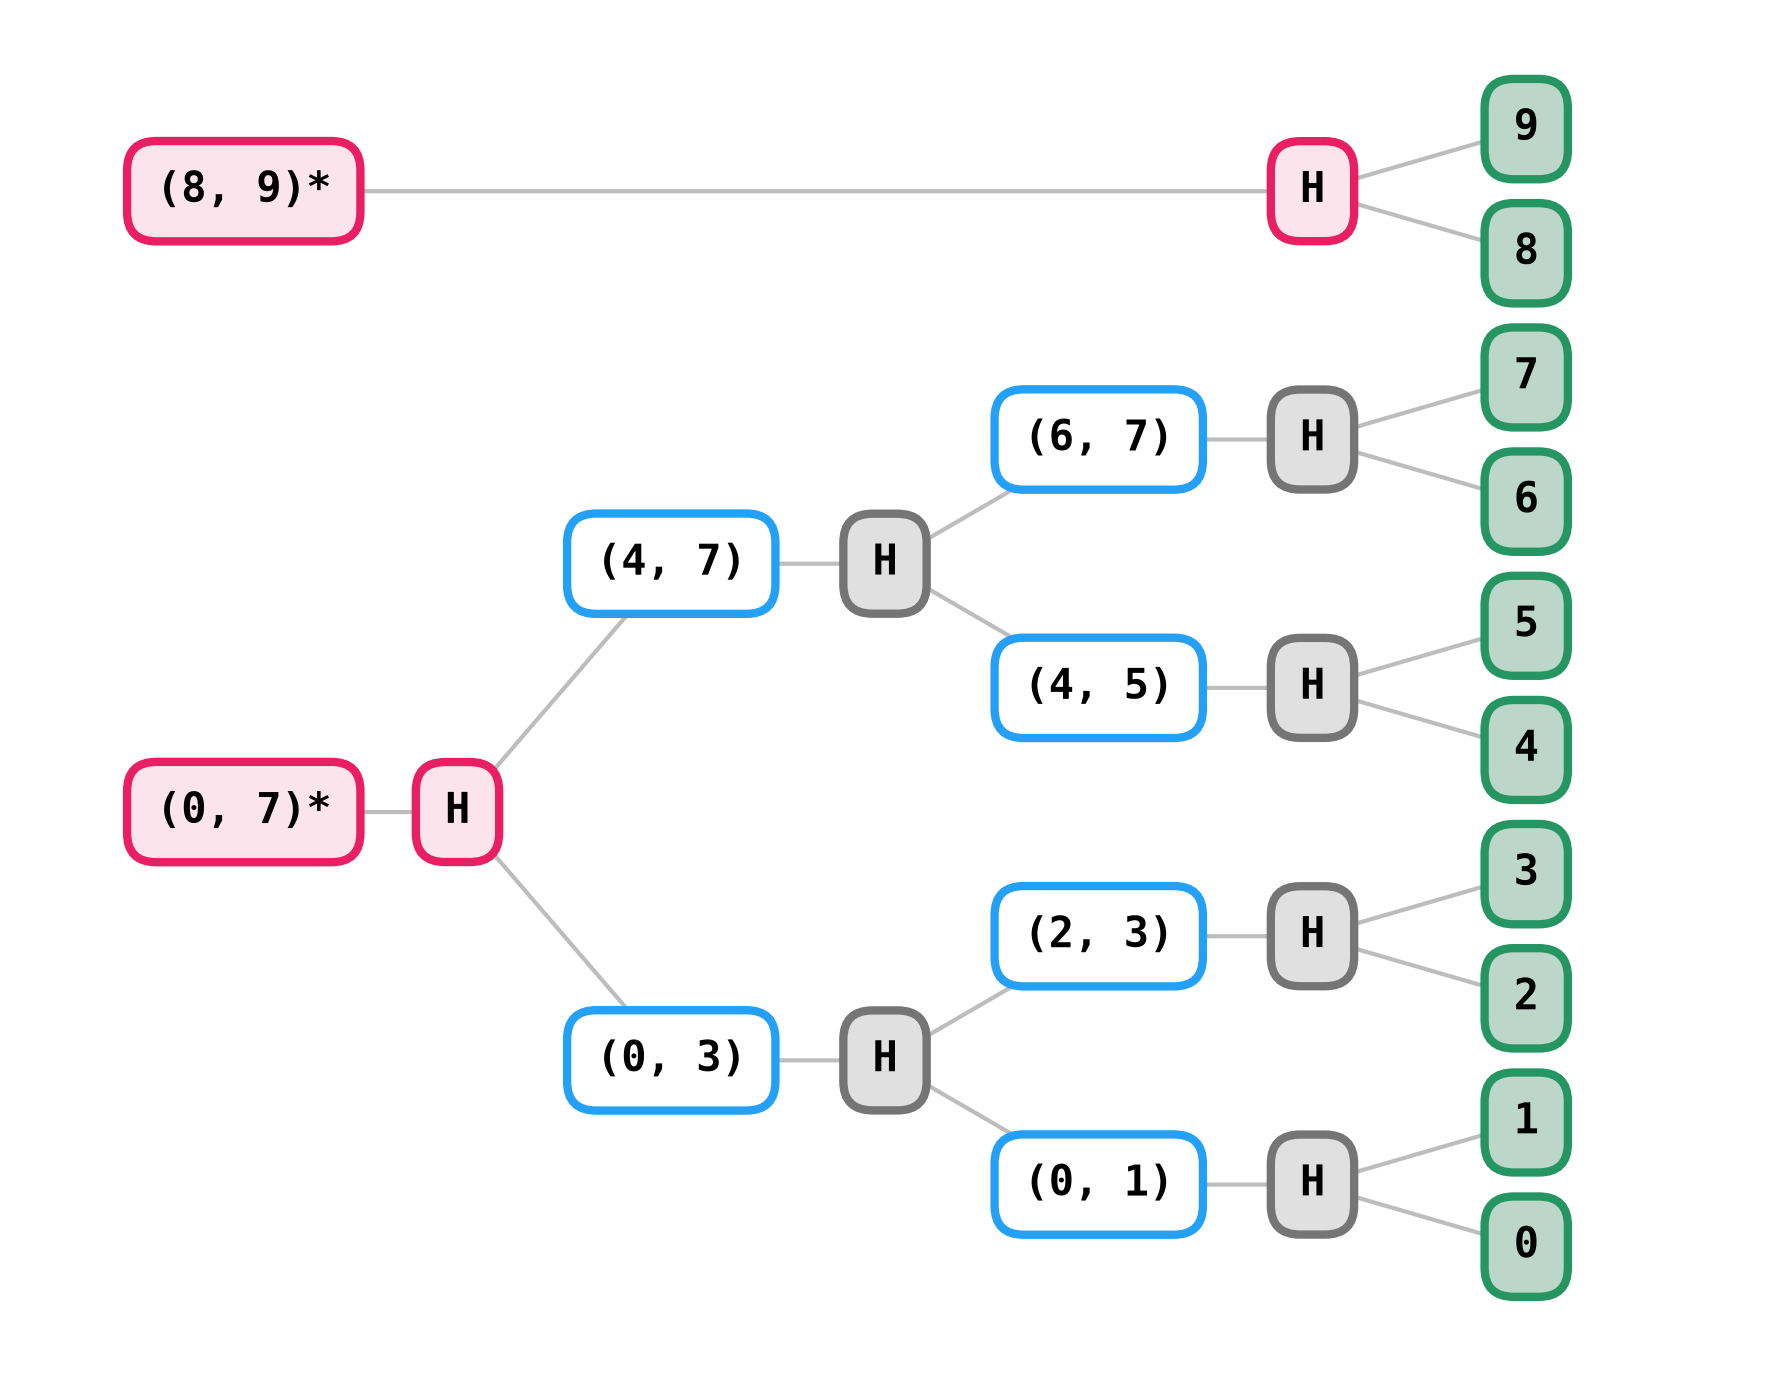

In [13]:
from helper.utils import calculate_total_leaves, mtl_print
%config InlineBackend.figure_format = "retina"

total_leaves = calculate_total_leaves(ladder.rungs)
ladder.total_leaves = total_leaves
mtl_print(ladder.total_leaves, ladder.rungs, target_width=6)

## 4. Verification

The verification operation of a full signature involves two main steps:
* Verifying the authentication path of the message relative to the ladder.
* Verifying the signature on the signed ladder using the signer's public key.

These checks are ordered so that a client validates the fast hash-related checks first. If these checks fail, the client can avoid the potentially expensive PQ signature check. Details can be found in Appendix in draft-kaizer-dnsop-ml-dsa-mtl-dnssec-03. 

The verification pipeline is as follows:
<div class="alert alert-block alert-warning" style="border-left: 20px solid #739e51; border-right: solid #739e51; border-top: solid #739e51; border-bottom: solid #739e51; background-color: #f6fcf2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #5d8043;">Verification</h3>
<ul>
    <li><strong>Section 4.1</strong> Validating Authentication Path</li>
        <ul>
            <li><strong>Section 4.1.1</strong> Leaf Node Hash</li>
            <li><strong>Section 4.1.2</strong> Iteratively Hashing with Sibling Nodes to Obtain Internal Nodes</li>
            <li><strong>Section 4.1.3</strong> Matching Target with Extracted Ladder Rung</li>
        </ul>
    <li><strong>Section 4.2</strong> Validating Ladder Signature Using Signer's Public Key</li>
</ul>
</div>

### 4.1 Validating Authentication Path

The verifier verifies the authentication path for a message relative to a rung. This verification operation has two main steps:
* First, `hash_leaf()` computes the leaf node hash value from the message. 
* Second, `hash_int()` computes internal node hash values using the leaf hash and successive sibling hashes extracted from the authentication path. If any internal node index matches the rung index, its hash is verified against the rung hash.

#### 4.1.1 Leaf Node Hash
The function below constructs the leaf node payload and executes the leaf hash operation using the specified algorithm and security parameter.

In [14]:
from helper.verifier import hash_leaf

# Leave the context string (ctx_msg) NULL
leaf_node = hash_leaf(
                    sid=authpath.sid,
                    leaf_index=int(authpath.leaf_index.hex(), 16),
                    randomizer=authpath.randomizer,
                    ctx_msg=b"",
                    message=message,
                    hash_alg=hash_alg,
                    n=n
)

# Update AuthPath instance
authpath.leaf_node = leaf_node
display(authpath.leaf_print())

"Leaf Node (9, 9)",Value


#### 4.1.2 Iteratively Hashing with Sibling Nodes to Obtain Internal Nodes

We next iteratively hash with sibling nodes by performing the following for each sibling node: 
  * Generate the hash payload.
  * Perform the internal hash operation.

In [15]:
from helper.verifier import calculate_internal_nodes

internal_nodes = calculate_internal_nodes(sid=authpath.sid, 
                                          leaf_index=authpath.leaf_index, 
                                          leaf_hash=authpath.leaf_node, 
                                          sibling_list=authpath.siblings_withindex, 
                                          hash_alg=hash_alg, 
                                          n=n)

# Update AuthPath instance
authpath.internal_nodes = internal_nodes

if not internal_nodes:
    print(f"The Leaf Node ({int.from_bytes(authpath.leaf_index, "big")}, {int.from_bytes(authpath.leaf_index, "big")}) does not have an authentication path.")
else:
    display(authpath.internal_print())

"Internal Node for Leaf (9, 9)",Value


#### 4.1.3 Matching Target with Extracted Ladder Rung 

Finally, the computed topmost internal node is compared to the target rung hash from the verified ladder to validate the authentication path. 

In [16]:
from helper.verifier import compare_with_rung

is_authpath_verified = compare_with_rung(leaf_index=authpath.leaf_index,
                        leaf_hash=authpath.leaf_node,
                        internal_nodes=authpath.internal_nodes,
                        target_rung_lindex=authpath.rung_lindex,
                        target_rung_rindex=authpath.rung_rindex,
                        rungs=ladder.rungs)

console = Console()
status_text = f"Authentication Path Verification {'[bold green]SUCCESS!![/bold green]' if is_authpath_verified else '[bold red]FAILED!![/bold red]'}"
console.print(Panel(status_text, title=">>> AuthPath Verification <<<", border_style="#3b82f6", expand=False))

╭────── >>> AuthPath Verification <<< ───────╮
│ Authentication Path Verification SUCCESS!! │
╰────────────────────────────────────────────╯

Now the authentication path of the message relative to the ladder is verified. The next step is to verify the ladder signature using the corresponding public key.

### 4.2 Validating Ladder Signature Using Signer's Public Key

#### Helper: check OpenSSL version

In [17]:
# Load the shared library
libcrypto = ctypes.CDLL("/usr/local/lib64/libcrypto.so.3")

# OpenSSL version: 0 maps to the OPENSSL_VERSION string constant
libcrypto.OpenSSL_version.restype = ctypes.c_char_p
version_text = libcrypto.OpenSSL_version(0) 

console = Console()
status_text = f"{version_text.decode("utf-8")}"
console.print(Panel(status_text, title=">>> OpenSSL Version <<<", border_style="#c084fc", expand=False))

╭─ >>> OpenSSL Version <<< ─╮
│ OpenSSL 3.6.0 1 Oct 2025  │
╰───────────────────────────╯

We configure OpenSSL parameters and map handlers to Python ctypes in the helper file verifier.py. We bind OpenSSL to validate the ladder signature.

#### Validating Ladder Signature

In [18]:
from helper.verifier import mldsa_verify_signature, slhdsa_verify_signature

def verify_signature(algo: str, pubkey: bytes, signature: bytes, message: bytes) -> bool:
    if algo.startswith("ML-DSA"):
        is_verified = mldsa_verify_signature(algorithm=algo, public_key=pubkey, ladder_sig=signature, ladder=message)
    else:
        raise ValueError(f"Unsupported algorithm {algo}.")
    return is_verified

In [19]:
is_verified = verify_signature(algo=sig_alg, pubkey=pubkey, signature=ladder.signature, message=ladder.val)

console = Console()
status_text = f"Ladder Signature Verification {'[bold green]SUCCESS!![/bold green]' if is_verified else '[bold red]FAILED!![/bold red]'}"
console.print(Panel(status_text, title=">>> Ladder Signature Verification <<<", border_style="#3b82f6", expand=False))

╭─ >>> Ladder Signature Verification <<< ─╮
│ Ladder Signature Verification SUCCESS!! │
╰─────────────────────────────────────────╯

## 📝 End of Demo

This demo has shown how an ML-DSA signature for the MTL is parsed into components and verified by: 
  * Verifying the message authentication path relative to a specific rung, and 
  * Validating the signed ladder using the corresponding public key